# CS781 Phase 1 · Decoder-only Transformer pretraining

A 16-block pre-norm decoder predicts the next BPE token at every position. Each block uses full causal multi-head attention with 16 heads, width 1,024 and a 4,096-wide GELU feed-forward layer. Input and output weights are tied, and positions use fixed sinusoidal encodings.

| Recorded setting | Value |
|---|---|
| Run | `decoder_004_mixed217m` |
| Trainable parameters | 217,860,096 |
| Vocabulary and context | 16,000 BPE IDs, 2,560 positions |
| Hardware | Two Tesla T4 GPUs with PyTorch DataParallel |
| Global microbatch × accumulation | 8 × 3 |
| Adam peak LR and floor | `3e-4` and `3e-5` |
| Applied input positions | 300,011,520 |
| Supervised training targets | 300,011,520 |
| Best held-out macro NLL | 1.387249 |

The saved execution continues the initial 50M chunk under the same 300M schedule. The cumulative stop is set to 300M just before the training call. Both chunks use the same run directory and optimizer protocol.

## Run setup

Use a Kaggle T4 ×2 session and attach the extracted `prep_002_mixed16k` preparation as input.
The four sources contribute equally. The setup writes the embedded implementation under
`/kaggle/working`, then validates the input manifest and configures the run. Leave the restore inputs unset for a new run. For a resume, supply the matching training backup in the input section.
Use the separate decoder evaluation notebook to score generated continuations.


## 1. Dependencies

Install `ijson` for the data helpers used by the notebook.


In [1]:
%pip install -q ijson


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.9/149.9 kB 4.0 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


## 2. Kaggle workspace and GPU inventory

Create the working source directory and record CUDA device names and available memory.


In [2]:
from pathlib import Path
import sys, json, pickle, shutil, time, math, gc, platform
from importlib.metadata import version
import numpy as np
SRC_DIR = Path('/kaggle/working/large_src')
SRC_DIR.mkdir(parents=True, exist_ok=True)
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
ROOT = Path('/kaggle/working/cs781_phase1')
ROOT.mkdir(parents=True, exist_ok=True)

import torch
assert torch.cuda.is_available() and torch.cuda.device_count() == 2, 'Select T4 x2 in Kaggle settings'
for j in range(torch.cuda.device_count()):
    print(j, torch.cuda.get_device_name(j), round(torch.cuda.get_device_properties(j).total_memory / 2**30, 2), 'GiB')
print('PyTorch:', torch.__version__, '| CUDA:', torch.version.cuda)


0 Tesla T4 14.56 GiB
1 Tesla T4 14.56 GiB
PyTorch: 2.11.0+cu128 | CUDA: 12.8


## 3. File and checksum utilities

Write JSON and checkpoint metadata atomically, hash artifacts and package saved run files.


In [3]:
%%writefile /kaggle/working/large_src/phase1_utils.py
"""Small file and JSON helpers used by the Phase-1 notebooks."""
import hashlib
import json
import os
import pickle
import zipfile
from pathlib import Path


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def text_hash(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def atomic_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
    os.replace(temporary, path)


def atomic_pickle(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    with open(temporary, "wb") as file:
        pickle.dump(value, file, protocol=pickle.HIGHEST_PROTOCOL)
        file.flush()
        os.fsync(file.fileno())
    os.replace(temporary, path)


def checked_json(path, value):
    path = Path(path)
    if path.exists() and read_json(path) != value:
        raise ValueError(f"Saved settings differ: {path}. Use a new experiment ID.")
    atomic_json(path, value)


def write_source(path, content):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    raw = content.encode("utf-8") if isinstance(content, str) else content
    if path.exists():
        if path.read_bytes() != raw:
            raise ValueError(f"Saved source differs: {path}. Keep its code or use a new experiment ID.")
        return
    path.write_bytes(raw)


def make_bundle(folder, output_path, archive_root):
    folder, output_path, archive_root = Path(folder), Path(output_path), Path(archive_root)
    temporary = output_path.with_suffix(".zip.tmp")
    with zipfile.ZipFile(temporary, "w", compression=zipfile.ZIP_STORED) as archive:
        for path in sorted(folder.rglob("*")):
            if path.is_file() and "__pycache__" not in path.parts and not path.name.endswith(".tmp"):
                archive.write(path, path.relative_to(archive_root))
    os.replace(temporary, output_path)
    return output_path


Overwriting /kaggle/working/large_src/phase1_utils.py


## 4. Input and restore utilities

Resolve extracted inputs and restore a compatible run into the working directory when a backup is supplied.


In [4]:
%%writefile /kaggle/working/large_src/phase1_paths.py
"""Restore extracted Kaggle input folders, without assuming the ZIP survives."""
import shutil
import zipfile
from pathlib import Path
from phase1_utils import sha256_file


def find_input_folder(folder_name, marker, explicit=None, identical_files=()):
    if explicit:
        folder = Path(explicit)
        if not (folder / marker).is_file():
            raise FileNotFoundError(f"Expected {marker} in {folder}")
        return folder
    matches = sorted({p.parent for p in Path("/kaggle/input").rglob(marker)
                      if p.parent.name == folder_name})
    if not matches:
        return None
    if len(matches) == 1:
        return matches[0]
    if identical_files and all(all((p / name).exists() for name in identical_files) for p in matches):
        fingerprints = [tuple(sha256_file(p / name) for name in identical_files) for p in matches]
        if len(set(fingerprints)) == 1:
            return matches[0]
    raise ValueError(f"Several input copies found. Set the explicit folder path: {matches}")


def restore_folder(destination, folder_name, marker, explicit=None):
    destination = Path(destination)
    if (destination / marker).exists():
        return destination
    source = find_input_folder(folder_name, marker, explicit)
    if source is not None:
        destination.mkdir(parents=True, exist_ok=True)
        shutil.copytree(source, destination, dirs_exist_ok=True)
        print("Restored extracted input folder:", source, flush=True)
    return destination


def restore_zip(zip_path, working_root):
    """Optional path for a ZIP that Kaggle did not extract automatically."""
    working_root = Path(working_root).resolve()
    with zipfile.ZipFile(zip_path) as archive:
        for member in archive.infolist():
            destination = (working_root / member.filename).resolve()
            if not destination.is_relative_to(working_root):
                raise ValueError("Unsafe archive path")
            if destination.exists() and not member.is_dir():
                raise ValueError(f"ZIP would overwrite {destination}; restore into a fresh working folder")
        archive.extractall(working_root)


Overwriting /kaggle/working/large_src/phase1_paths.py


## 5. Byte-BPE implementation

Load the course assignment tokenizer and restore its learned merges from the shared 16K state.


In [5]:
%%writefile /kaggle/working/large_src/a1_tokenizer.py
"""The assignment byte-BPE algorithm, with checkpoints between merges.

Pair counting, lexicographic tie breaking, non-overlapping replacements and
merge-order encoding are unchanged from the completed Phase-1/A3 tokenizer.
"""
import pickle
import re
import time
from collections import Counter
from pathlib import Path
from phase1_utils import atomic_pickle, sha256_file, text_hash


class A1BPETokenizer:
    def __init__(self):
        specials = ["<pad>", "<unk>", "<s>", "</s>"]
        self.vocab = [s.encode("utf-8") for s in specials]
        self.vocab += [bytes([b]) for b in range(256)]
        self.boundary_id = len(self.vocab)
        self.vocab.append(b"")
        self.names = [s.encode("utf-8") for s in specials]
        self.names += [bytes([b]) for b in range(256)]
        self.names.append(b"</w>")
        self.merges = {}
        self.vocab_size = len(self.vocab)

    def fit(self, text, vocab_size, checkpoint_path=None, checkpoint_merges=100,
            stop_after_merges=None):
        if vocab_size < 261:
            raise ValueError("Vocabulary must accommodate bytes and reserved tokens")
        signature = {"text_sha256": text_hash(text), "vocab_size": vocab_size,
                     "algorithm_source_sha256": sha256_file(__file__)}
        checkpoint_path = Path(checkpoint_path) if checkpoint_path is not None else None
        elapsed_before = 0.0
        if checkpoint_path is not None and checkpoint_path.exists():
            with open(checkpoint_path, "rb") as file:
                saved = pickle.load(file)
            if saved["signature"] != signature:
                raise ValueError("BPE checkpoint settings or source differ")
            self.__dict__.update(saved["tokenizer_state"])
            words = saved["words"]
            elapsed_before = saved["elapsed_seconds"]
            print("Resuming BPE vocabulary:", self.vocab_size, flush=True)
        else:
            if self.merges:
                raise ValueError("Use a fresh tokenizer or its saved fitting checkpoint")
            words = Counter(tuple(b + 4 for b in piece.encode("utf-8")) + (self.boundary_id,)
                            for piece in re.findall(r"\S+|\s+", text))
        started = time.monotonic()
        last_saved = started
        merges_this_call = 0
        commit_in_progress = False

        def snapshot():
            if checkpoint_path is not None:
                atomic_pickle(checkpoint_path, {"signature": signature,
                    "tokenizer_state": self.__dict__, "words": words,
                    "elapsed_seconds": elapsed_before + time.monotonic() - started})

        try:
            while len(self.vocab) < vocab_size:
                pair_counts = Counter()
                for symbols, frequency in words.items():
                    for pair in zip(symbols, symbols[1:]):
                        pair_counts[pair] += frequency
                if not pair_counts:
                    break
                pair = min(pair_counts, key=lambda p: (-pair_counts[p], self.names[p[0]], self.names[p[1]]))
                if pair_counts[pair] < 2:
                    break
                new_id = len(self.vocab)
                updated = Counter()
                for symbols, frequency in words.items():
                    result = []
                    j = 0
                    while j < len(symbols):
                        if j + 1 < len(symbols) and symbols[j:j + 2] == pair:
                            result.append(new_id)
                            j += 2
                        else:
                            result.append(symbols[j])
                            j += 1
                    updated[tuple(result)] += frequency
                # Commit the whole merge only after every word has been replaced.
                commit_in_progress = True
                self.vocab.append(self.vocab[pair[0]] + self.vocab[pair[1]])
                self.names.append(self.names[pair[0]] + self.names[pair[1]])
                self.merges[pair] = new_id
                self.vocab_size = len(self.vocab)
                words = updated
                commit_in_progress = False
                merges_this_call += 1
                if len(self.merges) % checkpoint_merges == 0 or time.monotonic() - last_saved >= 60:
                    snapshot()
                    print(f"BPE vocabulary {self.vocab_size:,}/{vocab_size:,} | "
                          f"elapsed {(elapsed_before + time.monotonic() - started)/60:.1f} min", flush=True)
                    last_saved = time.monotonic()
                if stop_after_merges is not None and merges_this_call >= stop_after_merges:
                    break
        finally:
            if not commit_in_progress:
                snapshot()
        return self

    def encode(self, text):
        result = []
        for piece in re.findall(r"\S+|\s+", text):
            symbols = [b + 4 for b in piece.encode("utf-8")] + [self.boundary_id]
            while len(symbols) > 1:
                candidates = [(self.merges[(a, b)], (a, b))
                              for a, b in zip(symbols, symbols[1:]) if (a, b) in self.merges]
                if not candidates:
                    break
                new_id, pair = min(candidates)
                merged = []
                j = 0
                while j < len(symbols):
                    if j + 1 < len(symbols) and (symbols[j], symbols[j + 1]) == pair:
                        merged.append(new_id)
                        j += 2
                    else:
                        merged.append(symbols[j])
                        j += 1
                symbols = merged
            result.extend(symbols)
        return result

    def decode(self, ids):
        return b"".join(self.vocab[i] for i in ids).decode("utf-8")


Overwriting /kaggle/working/large_src/a1_tokenizer.py


## 6. Token caches and source batches

Read the per-source arrays and sample deterministic context blocks while tracking source cursors.


In [6]:
%%writefile /kaggle/working/large_src/phase1_data.py
"""Stream legal documents, freeze document ownership, and build token caches."""
import json
import os
import re
import time
from functools import lru_cache
from pathlib import Path
import ijson
import numpy as np
from phase1_utils import atomic_json, checked_json, read_json, sha256_file, text_hash

DTYPE = np.dtype("<u2")


def is_validation(digest):
    return int(digest[:16], 16) % 20 == 0


def iter_records(path):
    with open(path, "rb") as file:
        first = file.read(4096).lstrip()[:1]
        file.seek(0)
        if first == b"[":
            records = ijson.items(file, "item")
        elif first == b"{":
            records = (record for _, record in ijson.kvitems(file, ""))
        else:
            raise ValueError("Expected a JSON list or an ID-to-record dictionary")
        for record in records:
            if not isinstance(record, dict) or not isinstance(record.get("text"), str):
                raise ValueError("Every document must contain a string 'text'")
            yield record


def audit_source(path, source, folder, signature, seen,
                 bpe_chars=500_000, val_chars=500_000, generation_examples=25):
    """Exact duplicates belong to the first source in the frozen source order."""
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    sample_path, manifest_path = folder / f"{source}_samples.json", folder / f"{source}_ownership.jsonl"
    if sample_path.exists():
        saved = read_json(sample_path)
        if saved["signature"] != signature or sha256_file(manifest_path) != saved["ownership_sha256"]:
            raise ValueError("Saved source audit differs")
        with open(manifest_path, encoding="utf-8") as file:
            for line in file:
                digest = json.loads(line)["full_text_sha256"]
                if digest in seen:
                    raise ValueError("Cross-source ownership contains a duplicate")
                seen.add(digest)
        return saved
    temporary = manifest_path.with_suffix(".jsonl.tmp")
    bpe_chunks, val_texts, prompts, truths = [], [], {}, {}
    counts = {"records": 0, "empty": 0, "duplicates": 0, "owned_documents": 0,
              "owned_training_documents": 0, "owned_validation_documents": 0,
              "owned_training_characters": 0, "owned_validation_characters": 0,
              "bpe_characters": 0, "validation_sample_characters": 0}
    last_print = time.monotonic()
    with open(temporary, "w", encoding="utf-8") as manifest:
        for index, record in enumerate(iter_records(path)):
            counts["records"] += 1
            text = record["text"]
            if not text.strip():
                counts["empty"] += 1
                continue
            digest = text_hash(text)
            if digest in seen:
                counts["duplicates"] += 1
                continue
            seen.add(digest)
            validation = is_validation(digest)
            manifest.write(json.dumps({"record_index": index, "full_text_sha256": digest,
                                       "validation": validation, "characters": len(text)}) + "\n")
            counts["owned_documents"] += 1
            key = "validation" if validation else "training"
            counts[f"owned_{key}_documents"] += 1
            counts[f"owned_{key}_characters"] += len(text)
            if not validation and counts["bpe_characters"] < bpe_chars:
                chunk = text[:min(4000, bpe_chars - counts["bpe_characters"])]
                bpe_chunks.append(chunk)
                counts["bpe_characters"] += len(chunk)
            if validation:
                if counts["validation_sample_characters"] < val_chars:
                    chunk = text[:min(20_000, val_chars - counts["validation_sample_characters"])]
                    val_texts.append(chunk)
                    counts["validation_sample_characters"] += len(chunk)
                if len(prompts) < generation_examples:
                    words = text.split(maxsplit=640)
                    if len(words) >= 640:
                        prompt_id = f"{source}_{len(prompts):04d}"
                        prompts[prompt_id] = {"text": " ".join(words[:512])}
                        truths[prompt_id] = {"text": " ".join(words[512:640])}
            if time.monotonic() - last_print >= 30:
                print(source, "| scanned", counts["records"], "| duplicates", counts["duplicates"], flush=True)
                last_print = time.monotonic()
        manifest.flush()
        os.fsync(manifest.fileno())
    os.replace(temporary, manifest_path)
    if counts["bpe_characters"] != bpe_chars or counts["validation_sample_characters"] != val_chars:
        raise ValueError(f"Sample quotas not met for {source}: {counts}")
    if len(prompts) != generation_examples:
        raise ValueError(f"Only {len(prompts)} suitable held-out prompts in {source}")
    saved = {"signature": signature, "statistics": counts, "bpe_chunks": bpe_chunks,
             "validation_texts": val_texts, "prompts": prompts, "truths": truths,
             "ownership_sha256": sha256_file(manifest_path)}
    atomic_json(sample_path, saved)
    return saved


def cached_encoder(tokenizer):
    @lru_cache(maxsize=200_000)
    def piece_ids(piece):
        return tuple(tokenizer.encode(piece))
    def encode(text):
        return [i for piece in re.findall(r"\S+|\s+", text) for i in piece_ids(piece)]
    return encode


def cache_metadata(binary, metadata_path, signature):
    if not Path(metadata_path).exists():
        return None
    metadata = read_json(metadata_path)
    if metadata["signature"] != signature:
        raise ValueError("Token-cache signature differs")
    if Path(binary).stat().st_size != metadata["token_count"] * DTYPE.itemsize:
        raise ValueError("Token-cache size differs")
    if sha256_file(binary) != metadata["sha256"]:
        raise ValueError("Token-cache checksum differs")
    return metadata


def build_source_cache(path, ownership_path, encode, folder, signature, target_tokens):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    binary, metadata_path = folder / "train.bin", folder / "train_metadata.json"
    old = cache_metadata(binary, metadata_path, signature)
    if old is not None:
        return old
    owners = {}
    with open(ownership_path, encoding="utf-8") as file:
        for line in file:
            row = json.loads(line)
            if not row["validation"]:
                owners[row["record_index"]] = row["full_text_sha256"]
    partial, progress_path = folder / "train.partial.bin", folder / "cache_progress.json"
    state = {"tokens_written": 0, "next_record_index": 0, "documents_encoded": 0,
             "last_document_truncated": False, "complete": False,
             "source_exhausted": False}
    if progress_path.exists():
        progress = read_json(progress_path)
        if progress["signature"] != signature:
            raise ValueError("Partial-cache signature differs")
        state = progress["state"]
    elif partial.exists():
        raise ValueError("Partial cache exists without progress metadata")
    if state["tokens_written"] and not partial.exists() and not binary.exists():
        raise ValueError("The partial cache needed for resumption is missing")
    if not state["complete"]:
        last_print = time.monotonic()
        with open(partial, "r+b" if partial.exists() else "w+b") as output:
            output.seek(state["tokens_written"] * DTYPE.itemsize)
            output.truncate()
            def snapshot():
                output.seek(state["tokens_written"] * DTYPE.itemsize)
                output.truncate()
                output.flush()
                os.fsync(output.fileno())
                atomic_json(progress_path, {"signature": signature, "state": state})
            try:
                for index, record in enumerate(iter_records(path)):
                    if index < state["next_record_index"]:
                        continue
                    if index in owners:
                        if text_hash(record["text"]) != owners[index]:
                            raise ValueError("Document content differs from the frozen audit")
                        ids = encode(record["text"]) + [3]
                        keep = ids[:target_tokens - state["tokens_written"]]
                        np.asarray(keep, dtype=DTYPE).tofile(output)
                        updated = dict(state)
                        updated["tokens_written"] += len(keep)
                        updated["documents_encoded"] += 1
                        updated["last_document_truncated"] = len(keep) < len(ids)
                        updated["next_record_index"] = index + 1
                        state = updated
                    else:
                        state["next_record_index"] = index + 1
                    if time.monotonic() - last_print >= 30:
                        snapshot()
                        print(signature["source"], "| cached", state["tokens_written"], "/", target_tokens, flush=True)
                        last_print = time.monotonic()
                    if state["tokens_written"] >= target_tokens:
                        state["complete"] = True
                        break
                else:
                    state["source_exhausted"] = True
                    state["complete"] = True
            finally:
                snapshot()
    source = partial if partial.exists() else binary
    if not source.exists() or state["tokens_written"] == 0:
        raise ValueError("No training tokens in this source")
    checksum = sha256_file(source)
    if partial.exists():
        os.replace(partial, binary)
    metadata = {"signature": signature, "dtype": DTYPE.str,
                "token_count": state["tokens_written"], "sha256": checksum,
                "requested_token_count": target_tokens,
                "source_exhausted": state["source_exhausted"], "statistics": state}
    atomic_json(metadata_path, metadata)
    return metadata


def build_validation_cache(texts, encode, folder, signature):
    folder = Path(folder)
    binary, metadata_path = folder / "validation.bin", folder / "validation_metadata.json"
    old = cache_metadata(binary, metadata_path, signature)
    if old is not None:
        return old
    temporary = binary.with_suffix(".bin.tmp")
    count = 0
    with open(temporary, "wb") as output:
        for text in texts:
            ids = encode(text) + [3]
            np.asarray(ids, dtype=DTYPE).tofile(output)
            count += len(ids)
    os.replace(temporary, binary)
    metadata = {"signature": signature, "dtype": DTYPE.str,
                "token_count": count, "sha256": sha256_file(binary), "documents": len(texts)}
    atomic_json(metadata_path, metadata)
    return metadata


def block_order(n_blocks, seed, source_number, epoch):
    return np.random.default_rng(seed + 100_000 * source_number + epoch).permutation(n_blocks)


def initial_cursors(sources):
    return {source: {"epoch": 0, "cursor": 0} for source in sources}


def mixed_batch(caches, cursors, source_order, source_offset, batch_size, block_size, seed, orders=None):
    xs, ys, counts = [], [], {source: 0 for source in source_order}
    for j in range(batch_size):
        source_number = (source_offset + j) % len(source_order)
        source = source_order[source_number]
        tokens = caches[source]
        n_blocks = (len(tokens) - 1) // block_size
        state = cursors[source]
        if state["cursor"] == n_blocks:
            state["epoch"] += 1
            state["cursor"] = 0
            if orders is not None:
                orders[source] = block_order(n_blocks, seed, source_number, state["epoch"])
        order = (block_order(n_blocks, seed, source_number, state["epoch"])
                 if orders is None else orders[source])
        index = int(order[state["cursor"]])
        state["cursor"] += 1
        start = index * block_size
        xs.append(np.asarray(tokens[start:start + block_size], dtype=np.int64))
        ys.append(np.asarray(tokens[start + 1:start + block_size + 1], dtype=np.int64))
        counts[source] += block_size
    return np.stack(xs), np.stack(ys), (source_offset + batch_size) % len(source_order), counts


Overwriting /kaggle/working/large_src/phase1_data.py


## 7. Model implementation

Define the Transformer blocks, attention masks, positional encodings and output projection used in this run.


In [7]:
%%writefile /kaggle/working/large_src/phase1_decoder.py
"""Phase 1 decoder, adapted from completed Assignment 3 Q1."""
import math
from dataclasses import dataclass
import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class LMConfig:
    vocab_size: int = 16000
    d_model: int = 1024
    n_layers: int = 16
    n_heads: int = 16
    d_ff: int = 4096
    max_seq_len: int = 2560
    dropout: float = 0.1
    norm_first: bool = True
    attention_impl: str = "sdpa"
    attention_scale: float = None
    embedding_scale: float = 32.0


class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, max_seq_len, dropout=0.0,
                 attention_scale=None, attention_impl="sdpa"):
        super().__init__()
        assert d_model % n_heads == 0
        if attention_impl not in ("manual", "sdpa"):
            raise ValueError("attention_impl must be manual or sdpa")
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.attention_scale = 1.0 / math.sqrt(self.d_head) if attention_scale is None else float(attention_scale)
        self.attention_impl = attention_impl
        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        if attention_impl == "manual":
            self.register_buffer("causal_mask", torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool)),
                                 persistent=False)

    def forward(self, x):
        B, T, C = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        if self.attention_impl == "manual":
            scores = (q @ k.transpose(-2, -1)) * self.attention_scale
            scores = scores.masked_fill(~self.causal_mask[:T, :T], float("-inf"))
            weights = self.attn_dropout(torch.softmax(scores, dim=-1))
            out = weights @ v
        else:
            out = F.scaled_dot_product_attention(
                q, k, v, is_causal=True, scale=self.attention_scale,
                dropout_p=self.attn_dropout.p if self.training else 0.0,
            )
        out = out.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.out_proj(out))


def sinusoidal_positional_encoding(max_len, d_model):
    position = torch.arange(max_len).unsqueeze(1).float()
    frequency = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
    pe = torch.zeros(max_len, d_model)
    pe[:, 0::2] = torch.sin(position * frequency)
    pe[:, 1::2] = torch.cos(position * frequency)
    return pe


class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(),
                                 nn.Linear(d_ff, d_model), nn.Dropout(dropout))

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.norm_first = cfg.norm_first
        self.ln1 = nn.LayerNorm(cfg.d_model)
        self.attn = CausalSelfAttention(cfg.d_model, cfg.n_heads, cfg.max_seq_len, cfg.dropout,
                                      cfg.attention_scale, cfg.attention_impl)
        self.ln2 = nn.LayerNorm(cfg.d_model)
        self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)

    def forward(self, x):
        if self.norm_first:
            x = x + self.attn(self.ln1(x))
            x = x + self.ffn(self.ln2(x))
        else:
            x = self.ln1(x + self.attn(x))
            x = self.ln2(x + self.ffn(x))
        return x


class DecoderLM(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.register_buffer("pos_emb", sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model),
                             persistent=False)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight

        # parameters() counts the tied matrix once.
        for parameter in self.parameters():
            if parameter.ndim > 1:
                nn.init.xavier_uniform_(parameter)
        for module in self.modules():
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, idx, last_positions=None):
        B, T = idx.shape
        if T > self.cfg.max_seq_len:
            raise ValueError("Input exceeds the configured context length")
        x = self.tok_emb(idx) * self.cfg.embedding_scale + self.pos_emb[:T].unsqueeze(0)
        for block in self.blocks:
            x = block(x)
        x = self.ln_f(x)
        if last_positions is not None:
            x = x[torch.arange(B, device=idx.device), last_positions]
        return self.head(x)


class ModelWithLoss(nn.Module):
    """Compute loss on each GPU before DataParallel gathers the small outputs."""
    def __init__(self, lm, use_amp=True):
        super().__init__()
        self.lm = lm
        self.use_amp = use_amp

    def forward(self, x, y):
        # Enter autocast in each worker thread; do not move the model to half().
        with torch.autocast("cuda", dtype=torch.float16, enabled=self.use_amp and x.is_cuda):
            logits = self.lm(x)
            loss = F.cross_entropy(logits.reshape(-1, self.lm.cfg.vocab_size), y.reshape(-1))
        return loss.unsqueeze(0)


Overwriting /kaggle/working/large_src/phase1_decoder.py


## 8. Training and checkpoint implementation

Track optimizer updates, sample source-balanced batches, evaluate held-out NLL and write resumable state.


In [8]:
%%writefile /kaggle/working/large_src/phase1_training.py
"""A3-style next-token training with equal-source batches and full checkpoints."""
import copy
import gc
import math
import os
import random
import signal
import time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from phase1_utils import atomic_json, checked_json, read_json, sha256_file
from phase1_data import DTYPE, block_order, initial_cursors, mixed_batch
from phase1_decoder import LMConfig, DecoderLM, ModelWithLoss


def cosine_multiplier(step, total_steps, warmup_steps, minimum_fraction):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = min(1.0, (step - warmup_steps) / max(1, total_steps - warmup_steps))
    return minimum_fraction + (1 - minimum_fraction) * 0.5 * (1 + math.cos(math.pi * progress))


def atomic_torch_save(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    with open(temporary, "wb") as file:
        torch.save(value, file)
        file.flush()
        os.fsync(file.fileno())
    os.replace(temporary, path)


def load_caches(prep_dir):
    prep_dir = Path(prep_dir)
    manifest = read_json(prep_dir / "cache_manifest.json")
    training, validation = {}, {}
    for source in manifest["source_order"]:
        training[source] = np.memmap(prep_dir / "caches" / source / "train.bin", dtype=DTYPE, mode="r")
        validation[source] = np.memmap(prep_dir / "caches" / source / "validation.bin", dtype=DTYPE, mode="r")
    return manifest, training, validation


@torch.no_grad()
def evaluate_sources(loss_model, caches, block_size, batch_size, device):
    loss_model.eval()
    measurements = {}
    for source, tokens in caches.items():
        loss_sum, targets = 0.0, 0
        for start in range(0, len(tokens) - 1, block_size * batch_size):
            lengths = [min(block_size, len(tokens) - 1 - offset)
                       for offset in range(start, min(len(tokens) - 1, start + block_size * batch_size), block_size)]
            # Full blocks can be batched; the last short block is measured alone.
            full_lengths = [length for length in lengths if length == block_size]
            if full_lengths:
                offsets = [start + j * block_size for j in range(len(full_lengths))]
                x = np.stack([np.asarray(tokens[o:o + block_size], dtype=np.int64) for o in offsets])
                y = np.stack([np.asarray(tokens[o + 1:o + block_size + 1], dtype=np.int64) for o in offsets])
                xt, yt = torch.from_numpy(x).to(device), torch.from_numpy(y).to(device)
                loss_sum += float(loss_model(xt, yt).mean().item()) * y.size
                targets += y.size
            if lengths and lengths[-1] < block_size:
                offset = start + (len(lengths) - 1) * block_size
                xt = torch.from_numpy(np.asarray(tokens[offset:-1], dtype=np.int64)[None]).to(device)
                yt = torch.from_numpy(np.asarray(tokens[offset + 1:], dtype=np.int64)[None]).to(device)
                loss_sum += float(loss_model(xt, yt).mean().item()) * yt.numel()
                targets += yt.numel()
        if targets != len(tokens) - 1 or not math.isfinite(loss_sum):
            raise FloatingPointError("Invalid validation loss or target count")
        nll = loss_sum / targets
        measurements[source] = {"nll": nll, "perplexity": math.exp(nll), "targets": targets}
    macro_nll = sum(row["nll"] for row in measurements.values()) / len(measurements)
    token_nll = sum(row["nll"] * row["targets"] for row in measurements.values()) / sum(row["targets"] for row in measurements.values())
    return {"validation_nll": macro_nll, "validation_perplexity": math.exp(macro_nll),
            "validation_token_nll": token_nll, "sources": measurements}


def train_run(prep_dir, run_dir, model_config, settings, stop_after_tokens,
              max_run_hours=10.0, cpu_test=False):
    run_dir = Path(run_dir)
    run_dir.mkdir(parents=True, exist_ok=True)
    if not cpu_test and (not torch.cuda.is_available() or torch.cuda.device_count() < 2):
        raise RuntimeError("Select T4 x2 for full training")
    device = torch.device("cpu" if cpu_test else "cuda:0")
    manifest, train_caches, val_caches = load_caches(prep_dir)
    cfg = LMConfig(**model_config)
    sources = manifest["source_order"]
    batch_size = settings["global_batch_size"]
    accumulation = settings["gradient_accumulation_steps"]
    sequences_per_update = batch_size * accumulation
    assert batch_size % 2 == 0 and sequences_per_update % len(sources) == 0
    tokens_per_update = sequences_per_update * cfg.max_seq_len
    total_steps = math.ceil(settings["planned_training_tokens"] / tokens_per_update)
    warmup_steps = max(1, int(total_steps * settings["warmup_fraction"]))
    minimum_fraction = settings["minimum_learning_rate"] / settings["learning_rate"]
    assert 0 < minimum_fraction < 1
    assert all((len(tokens) - 1) // cfg.max_seq_len > 0 for tokens in train_caches.values())
    protocol = {"model_config": model_config, "settings": settings,
                "cache_manifest": manifest, "tokens_per_optimizer_update": tokens_per_update,
                "planned_optimizer_updates": total_steps, "warmup_optimizer_updates": warmup_steps,
                "decoder_source_sha256": sha256_file(Path(__file__).with_name("phase1_decoder.py")),
                "data_source_sha256": sha256_file(Path(__file__).with_name("phase1_data.py")),
                "trainer_source_sha256": sha256_file(__file__),
                "selection_metric": "Equal-source mean validation NLL; same frozen tokenizer"}
    checked_json(run_dir / "protocol.json", protocol)
    seed = settings["seed"]
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if not cpu_test:
        torch.cuda.manual_seed_all(seed)
    lm = DecoderLM(cfg)
    n_parameters = sum(p.numel() for p in lm.parameters())
    if not cpu_test:
        assert n_parameters == 217_860_096
    wrapped = ModelWithLoss(lm, use_amp=not cpu_test).to(device)
    model = wrapped if cpu_test else nn.DataParallel(wrapped, device_ids=[0, 1])
    optimizer = torch.optim.Adam(model.parameters(), lr=settings["learning_rate"],
                                 betas=tuple(settings["adam_betas"]), eps=settings["adam_eps"])
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer,
        lambda step: cosine_multiplier(step, total_steps, warmup_steps, minimum_fraction))
    scaler = torch.amp.GradScaler("cuda", enabled=not cpu_test)
    state = {"optimizer_updates": 0, "attempted_optimizer_updates": 0,
             "tokens_processed": 0, "tokens_in_applied_updates": 0, "skipped_optimizer_updates": 0,
             "cursors": initial_cursors(sources), "source_offset": 0,
             "processed_source_targets": {source: 0 for source in sources},
             "applied_source_targets": {source: 0 for source in sources},
             "last_validation_tokens": 0, "last_checkpoint_tokens": 0,
             "best_validation_nll": None, "window_loss": 0.0, "window_attempts": 0}
    history = []
    last_path = run_dir / "last.pt"
    resumed_from = None
    if last_path.exists():
        checkpoint = torch.load(last_path, map_location="cpu", weights_only=False)
        if checkpoint["protocol"] != protocol:
            raise ValueError("Checkpoint protocol differs")
        lm.load_state_dict(checkpoint["model_state"], strict=True)
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        scheduler.load_state_dict(checkpoint["scheduler_state"])
        scaler.load_state_dict(checkpoint["scaler_state"])
        state, history = checkpoint["training_state"], checkpoint["history"]
        random.setstate(checkpoint["rng_state"]["python"])
        np.random.set_state(checkpoint["rng_state"]["numpy"])
        torch.set_rng_state(checkpoint["rng_state"]["torch_cpu"])
        if not cpu_test:
            torch.cuda.set_rng_state_all(checkpoint["rng_state"]["torch_cuda"])
        resumed_from = str(last_path)
        del checkpoint
    orders = {source: block_order((len(train_caches[source]) - 1) // cfg.max_seq_len,
                                 seed, j, state["cursors"][source]["epoch"])
              for j, source in enumerate(sources)}
    initial_processed, initial_applied = state["tokens_processed"], state["tokens_in_applied_updates"]
    stop_requested = False
    def request_pause(signum, frame):
        nonlocal stop_requested
        stop_requested = True
        print("Pause requested; finishing this optimizer attempt and saving.", flush=True)
    previous_handler = signal.getsignal(signal.SIGINT)
    signal.signal(signal.SIGINT, request_pause)
    started = time.monotonic()
    last_saved_time = started

    def save_checkpoint():
        nonlocal last_saved_time
        state["last_checkpoint_tokens"] = state["tokens_in_applied_updates"]
        optimizer.zero_grad(set_to_none=True)
        rng = {"python": random.getstate(), "numpy": np.random.get_state(),
               "torch_cpu": torch.get_rng_state(),
               "torch_cuda": [] if cpu_test else torch.cuda.get_rng_state_all()}
        atomic_torch_save(last_path, {"protocol": protocol, "model_state": lm.state_dict(),
            "optimizer_state": optimizer.state_dict(), "scheduler_state": scheduler.state_dict(),
            "scaler_state": scaler.state_dict(), "training_state": copy.deepcopy(state),
            "history": history, "rng_state": rng})
        atomic_json(run_dir / "history.json", history)
        last_saved_time = time.monotonic()
        print("Saved checkpoint at", state["tokens_in_applied_updates"], "targets", flush=True)

    def record_validation():
        measured = evaluate_sources(wrapped, val_caches, cfg.max_seq_len,
                                    settings["validation_batch_size"], device)
        row = {"type": "validation", "optimizer_updates": state["optimizer_updates"],
               "tokens_in_applied_updates": state["tokens_in_applied_updates"], **measured}
        history.append(row)
        state["last_validation_tokens"] = state["tokens_in_applied_updates"]
        if state["best_validation_nll"] is None or measured["validation_nll"] < state["best_validation_nll"]:
            state["best_validation_nll"] = measured["validation_nll"]
            atomic_torch_save(run_dir / "best_model.pt", {"model_config": model_config,
                "model_state": lm.state_dict(), "tokenizer_signature": manifest["tokenizer_signature"],
                "validation_result": row})
        atomic_json(run_dir / "history.json", history)
        print("Validation", state["tokens_in_applied_updates"], "| macro NLL", measured["validation_nll"],
              "| source NLLs", {k: round(v["nll"], 4) for k, v in measured["sources"].items()}, flush=True)
        model.train()

    run_limit = min(stop_after_tokens, settings["planned_training_tokens"])
    exit_reason = "requested_token_chunk_complete"
    print("Parameters:", n_parameters, "| targets/update:", tokens_per_update,
          "| planned updates:", total_steps, "| warmup:", warmup_steps, flush=True)
    try:
        if not history:
            record_validation()
            save_checkpoint()
        while state["tokens_in_applied_updates"] < run_limit:
            if stop_requested or time.monotonic() - started >= max_run_hours * 3600:
                exit_reason = "manual_pause" if stop_requested else "time_cap"
                break
            model.train()
            optimizer.zero_grad(set_to_none=True)
            update_loss = 0.0
            update_counts = {source: 0 for source in sources}
            used_lr = optimizer.param_groups[0]["lr"]
            for _ in range(accumulation):
                xa, ya, state["source_offset"], counts = mixed_batch(train_caches, state["cursors"],
                    sources, state["source_offset"], batch_size, cfg.max_seq_len, seed, orders)
                x, y = torch.from_numpy(xa).to(device), torch.from_numpy(ya).to(device)
                loss = model(x, y).mean()
                if not torch.isfinite(loss).item():
                    raise FloatingPointError("Nonfinite training loss; resume from the last saved checkpoint")
                update_loss += float(loss.item()) / accumulation
                scaler.scale(loss / accumulation).backward()
                state["tokens_processed"] += y.numel()
                for source in sources:
                    state["processed_source_targets"][source] += counts[source]
                    update_counts[source] += counts[source]
            assert set(update_counts.values()) == {tokens_per_update // len(sources)}
            scaler.unscale_(optimizer)
            norm = torch.nn.utils.clip_grad_norm_(model.parameters(), settings["gradient_clip_norm"])
            previous_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            skipped = scaler.get_scale() < previous_scale
            state["attempted_optimizer_updates"] += 1
            if skipped:
                state["skipped_optimizer_updates"] += 1
            else:
                state["optimizer_updates"] += 1
                state["tokens_in_applied_updates"] += tokens_per_update
                for source in sources:
                    state["applied_source_targets"][source] += update_counts[source]
                scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            state["window_loss"] += update_loss
            state["window_attempts"] += 1
            if not skipped and state["optimizer_updates"] % settings["log_every_updates"] == 0:
                row = {"type": "training", "optimizer_updates": state["optimizer_updates"],
                    "tokens_in_applied_updates": state["tokens_in_applied_updates"],
                    "train_nll_window": state["window_loss"] / state["window_attempts"],
                    "learning_rate_used": used_lr, "gradient_scale": scaler.get_scale(),
                    "gradient_norm_before_clipping": float(norm.item()) if torch.isfinite(norm).item() else None,
                    "skipped_optimizer_updates": state["skipped_optimizer_updates"],
                    "elapsed_seconds_this_invocation": time.monotonic() - started}
                history.append(row)
                print("Update", row["optimizer_updates"], "| targets", row["tokens_in_applied_updates"],
                      "| train NLL", round(row["train_nll_window"], 4), "| LR", used_lr, flush=True)
                state["window_loss"], state["window_attempts"] = 0.0, 0
            if state["tokens_in_applied_updates"] - state["last_validation_tokens"] >= settings["validate_every_tokens"]:
                record_validation()
            if (state["tokens_in_applied_updates"] - state["last_checkpoint_tokens"] >= settings["checkpoint_every_tokens"]
                    or time.monotonic() - last_saved_time >= settings["checkpoint_every_seconds"]):
                save_checkpoint()
            if state["skipped_optimizer_updates"] >= settings["maximum_skipped_updates"]:
                exit_reason = "too_many_skipped_updates"
                break
        if state["last_validation_tokens"] != state["tokens_in_applied_updates"]:
            record_validation()
        save_checkpoint()
    finally:
        signal.signal(signal.SIGINT, previous_handler)
    elapsed = time.monotonic() - started
    summary = {"exit_reason": exit_reason, "resumed_from": resumed_from,
        "parameters": n_parameters, "training_state": state,
        "requested_chunk_end_tokens": stop_after_tokens,
        "training_loop_elapsed_seconds_this_invocation": elapsed,
        "new_tokens_in_applied_updates": state["tokens_in_applied_updates"] - initial_applied,
        "new_tokens_processed": state["tokens_processed"] - initial_processed,
        "targets_per_second": (state["tokens_processed"] - initial_processed) / max(elapsed, 1e-8),
        "torch_version": str(torch.__version__), "cuda_version": torch.version.cuda}
    atomic_json(run_dir / "run_summary.json", summary)
    summaries_path = run_dir / "training_invocations.json"
    summaries = read_json(summaries_path) if summaries_path.exists() else []
    summaries.append(summary)
    atomic_json(summaries_path, summaries)
    del model, wrapped, lm, optimizer, scheduler, scaler
    gc.collect()
    if not cpu_test:
        torch.cuda.empty_cache()
    return summary


Overwriting /kaggle/working/large_src/phase1_training.py


## 9. Numerical and throughput probes

Check causality, padding and attention behavior, then measure candidate batch sizes. The fitting probes use temporary weights.


In [9]:
%%writefile /kaggle/working/large_src/phase1_probes.py
"""Discardable fitting and throughput checks before the real training run."""
import gc
import math
import time
from dataclasses import asdict
import numpy as np
import torch
import torch.nn as nn
from phase1_data import block_order, initial_cursors, mixed_batch
from phase1_decoder import LMConfig, DecoderLM, ModelWithLoss


def require_two_gpus():
    if not torch.cuda.is_available() or torch.cuda.device_count() != 2:
        raise RuntimeError("Select the Kaggle T4 x2 accelerator first")


def gpu_memory():
    return [{"gpu": j, "name": torch.cuda.get_device_name(j),
             "total_gib": torch.cuda.get_device_properties(j).total_memory / 2**30,
             "peak_allocated_gib": torch.cuda.max_memory_allocated(j) / 2**30,
             "peak_reserved_gib": torch.cuda.max_memory_reserved(j) / 2**30}
            for j in range(torch.cuda.device_count())]


def fitting_check(model_config, tokens, steps=250, sequence_length=256, seed=42):
    """Fit one short batch. This model is discarded; no weights enter the run."""
    require_two_gpus()
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    probe_config = dict(model_config, dropout=0.0)
    lm = wrapped = model = optimizer = scaler = None
    try:
        lm = DecoderLM(LMConfig(**probe_config)).cuda()
        assert sum(p.numel() for p in lm.parameters()) == 217_860_096
        wrapped = ModelWithLoss(lm)
        model = nn.DataParallel(wrapped, device_ids=[0, 1])
        optimizer = torch.optim.Adam(model.parameters(), lr=3e-4, betas=(0.9, 0.999), eps=1e-8)
        scaler = torch.amp.GradScaler("cuda")
        # The same one-sequence batch is copied to both GPUs.
        x = torch.from_numpy(np.asarray(tokens[:sequence_length], dtype=np.int64)[None].copy()).cuda()
        y = torch.from_numpy(np.asarray(tokens[1:sequence_length + 1], dtype=np.int64)[None].copy()).cuda()
        x, y = x.repeat(2, 1), y.repeat(2, 1)
        if x.shape[1] != sequence_length:
            raise ValueError("Fitting probe needs a complete short sequence")
        rows, applied, skipped = [], 0, 0
        started = time.monotonic()
        model.train()
        while applied < steps:
            optimizer.zero_grad(set_to_none=True)
            loss = model(x, y).mean()
            if not torch.isfinite(loss).item():
                raise FloatingPointError("Nonfinite fitting-probe loss")
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            previous_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            if scaler.get_scale() < previous_scale:
                skipped += 1
                if skipped > 20:
                    raise FloatingPointError("Fitting probe skipped more than 20 updates")
                continue
            applied += 1
            if applied == 1 or applied % 25 == 0 or applied == steps:
                row = {"step": applied, "nll_before_update": float(loss.item()),
                       "gradient_norm_before_clip": float(norm.item()), "scale": scaler.get_scale()}
                rows.append(row)
                print("Fitting probe:", row, flush=True)
        model.eval()
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            logits = lm(x[:1])
            final_nll = float(torch.nn.functional.cross_entropy(logits.flatten(0, 1), y[:1].flatten()).item())
            accuracy = float((logits.argmax(-1) == y[:1]).float().mean().item())
        result = {"type": "discarded_single_batch_fitting_check", "probe_config": probe_config,
                  "sequence_length": sequence_length, "applied_updates": applied,
                  "skipped_updates": skipped, "final_nll": final_nll, "accuracy": accuracy,
                  "passed": final_nll < 1.0 and accuracy >= 0.8, "history": rows,
                  "elapsed_seconds": time.monotonic() - started}
        if not result["passed"]:
            print("Fitting gate did not pass; share this result before full training.", flush=True)
        return result
    finally:
        lm = wrapped = model = optimizer = scaler = None
        gc.collect()
        torch.cuda.empty_cache()


def benchmark_microbatches(model_config, caches, source_order, candidates=(2, 4, 8, 12),
                           effective_sequences=24, warmup_updates=2, measured_updates=3, seed=42):
    """Measure complete accumulated updates, including DP and Adam overhead."""
    require_two_gpus()
    assert model_config["max_seq_len"] == 2560
    results = []
    for batch_size in candidates:
        assert batch_size % 2 == 0 and effective_sequences % batch_size == 0
        accumulation = effective_sequences // batch_size
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        lm = wrapped = model = optimizer = scaler = None
        row = {"global_microbatch": batch_size, "accumulation_steps": accumulation,
               "effective_sequences": effective_sequences,
               "targets_per_update": effective_sequences * model_config["max_seq_len"]}
        try:
            lm = DecoderLM(LMConfig(**model_config)).cuda()
            assert sum(p.numel() for p in lm.parameters()) == 217_860_096
            wrapped = ModelWithLoss(lm)
            model = nn.DataParallel(wrapped, device_ids=[0, 1])
            optimizer = torch.optim.Adam(model.parameters(), lr=3e-4, betas=(0.9, 0.999), eps=1e-8)
            scaler = torch.amp.GradScaler("cuda")
            cursors, offset = initial_cursors(source_order), 0
            orders = {s: block_order((len(caches[s]) - 1) // 2560, seed, j, 0)
                      for j, s in enumerate(source_order)}
            model.train()
            def complete_update():
                nonlocal offset
                optimizer.zero_grad(set_to_none=True)
                for _ in range(accumulation):
                    xa, ya, offset, _ = mixed_batch(caches, cursors, source_order, offset,
                                                    batch_size, 2560, seed, orders)
                    x, y = torch.from_numpy(xa).cuda(), torch.from_numpy(ya).cuda()
                    loss = model(x, y).mean()
                    if not torch.isfinite(loss).item():
                        raise FloatingPointError("Nonfinite benchmark loss")
                    scaler.scale(loss / accumulation).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                old_scale = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                return scaler.get_scale() < old_scale
            warmup_skips = 0
            # Allocate Adam's moments before measuring memory or throughput.
            applied_warmup = 0
            while applied_warmup < warmup_updates:
                skipped = complete_update()
                warmup_skips += int(skipped)
                applied_warmup += int(not skipped)
                if warmup_skips > 20:
                    raise FloatingPointError("Excessive overflow in benchmark warmup")
            for j in (0, 1):
                torch.cuda.synchronize(j)
                torch.cuda.reset_peak_memory_stats(j)
            started = time.monotonic()
            measured_skips = sum(int(complete_update()) for _ in range(measured_updates))
            for j in (0, 1):
                torch.cuda.synchronize(j)
            elapsed = time.monotonic() - started
            memory = gpu_memory()
            headroom_ok = all(m["peak_reserved_gib"] <= 0.90 * m["total_gib"] for m in memory)
            row.update(status="ok", elapsed_seconds=elapsed, gpu_memory=memory,
                       warmup_skipped_updates=warmup_skips, measured_skipped_updates=measured_skips,
                       targets_per_second=measured_updates * row["targets_per_update"] / elapsed,
                       eligible=headroom_ok and measured_skips == 0)
        except torch.cuda.OutOfMemoryError:
            row.update(status="out_of_memory", eligible=False, gpu_memory=gpu_memory())
        except FloatingPointError as error:
            row.update(status="numerical_failure", eligible=False, error=str(error))
        finally:
            # Drop the closure too: it references the large probe objects.
            if "complete_update" in locals():
                complete_update = None
            lm = wrapped = model = optimizer = scaler = None
            gc.collect()
            torch.cuda.empty_cache()
        results.append(row)
        print("Microbatch benchmark:", row, flush=True)
    eligible = [row for row in results if row["eligible"]]
    if not eligible:
        raise RuntimeError(f"No safe microbatch found. Share these measurements: {results}")
    chosen = max(eligible, key=lambda row: row["targets_per_second"])
    return {"model_config": model_config, "torch_version": str(torch.__version__),
            "cuda_version": torch.version.cuda, "results": results, "chosen": chosen,
            "note": "Benchmark weights are discarded; context/model/effective batch stayed fixed."}


Overwriting /kaggle/working/large_src/phase1_probes.py


## 10. Generation implementation

Decode from the selected weights and save completed batches together with word counts and termination reasons.


In [10]:
%%writefile /kaggle/working/large_src/phase1_generation.py
"""Manual batched autoregressive decoding; no external generation model."""
import math
import time
from pathlib import Path
import torch
from phase1_utils import atomic_json, read_json, checked_json, text_hash


def sample_next(logits, mode, temperature, top_k, top_p, generator):
    if mode == "greedy":
        return int(logits.argmax().item())
    scaled = logits.float() / temperature
    if mode == "top_k":
        values, indices = scaled.topk(min(top_k, scaled.numel()))
        position = torch.multinomial(torch.softmax(values, dim=-1), 1, generator=generator)
        return int(indices[position].item())
    if mode == "top_p":
        values, indices = scaled.sort(descending=True)
        probabilities = torch.softmax(values, dim=-1)
        # Retain the first token that takes cumulative probability over p.
        remove = probabilities.cumsum(-1) - probabilities >= top_p
        values[remove] = -float("inf")
        position = torch.multinomial(torch.softmax(values, dim=-1), 1, generator=generator)
        return int(indices[position].item())
    raise ValueError("Unknown decoding mode")


def decoded_text(tokenizer, ids):
    # Byte BPE can temporarily end partway through a UTF-8 character.
    raw = b"".join(tokenizer.vocab[i] for i in ids if i >= 4)
    return raw.decode("utf-8", errors="replace")


@torch.no_grad()
def generate_predictions(model, tokenizer, prompts, output_dir, protocol, batch_size=4,
                         max_new_tokens=1024, target_words=128, seed=1234):
    """Save after complete fixed batches, so interrupted groups can be redone."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    device = next(model.parameters()).device
    model.eval()
    ids = list(prompts)
    frozen = {**protocol, "prompt_sha256": text_hash(__import__("json").dumps(prompts, sort_keys=True)),
              "prompt_id_order": ids,
              "batch_size": batch_size, "max_new_tokens": max_new_tokens,
              "target_words": target_words, "seed": seed, "context": model.cfg.max_seq_len,
              "torch_version": str(torch.__version__)}
    checked_json(output_dir / "protocol.json", frozen)
    progress_path = output_dir / "progress.json"
    progress = read_json(progress_path) if progress_path.exists() else {"rows": {}}
    rows = progress["rows"]
    if set(rows) - set(ids):
        raise ValueError("Generation progress contains unknown IDs")
    started = time.monotonic()
    for start in range(0, len(ids), batch_size):
        group = ids[start:start + batch_size]
        done = [key in rows for key in group]
        if all(done):
            continue
        if any(done):
            raise ValueError("Partial batch in saved progress; expected atomic group commits")
        contexts = [tokenizer.encode(prompts[key]["text"]) for key in group]
        generated = [[] for _ in group]
        finished = [False] * len(group)
        stop_reasons = ["token_cap"] * len(group)
        generators = [torch.Generator(device=device).manual_seed(seed + int(text_hash(key)[:8], 16))
                      for key in group]
        original_lengths = [len(context) for context in contexts]
        cropped = [max(0, length - model.cfg.max_seq_len) for length in original_lengths]
        for _ in range(max_new_tokens):
            active = [j for j in range(len(group)) if not finished[j]]
            if not active:
                break
            windows = [contexts[j][-model.cfg.max_seq_len:] for j in active]
            if any(not window for window in windows):
                raise ValueError("Empty tokenized prompt")
            lengths = torch.tensor([len(window) for window in windows], device=device)
            x = torch.zeros((len(active), int(lengths.max().item())), dtype=torch.long, device=device)
            for k, window in enumerate(windows):
                x[k, :len(window)] = torch.tensor(window, device=device)
            # Right padding occurs strictly AFTER the real last position.
            # Causal attention prevents it affecting any real-position output.
            with torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
                logits = model(x, last_positions=lengths - 1).float()
            for k, j in enumerate(active):
                logits[k, :3] = -float("inf")  # never emit PAD / UNK / BOS
                text = decoded_text(tokenizer, generated[j])
                if len(text.split()) < target_words:
                    logits[k, 3] = -float("inf")
                token = sample_next(logits[k], protocol["mode"], protocol.get("temperature", 1.0),
                                    protocol.get("top_k", 50), protocol.get("top_p", 0.95), generators[j])
                if token == 3:
                    finished[j], stop_reasons[j] = True, "eos_after_word_target"
                    continue
                generated[j].append(token)
                contexts[j].append(token)
                cropped[j] += int(len(contexts[j]) > model.cfg.max_seq_len)
                text = decoded_text(tokenizer, generated[j])
                # Wait for the 128th word to be complete: whitespace or a
                # subsequent word. At the cap, a final word may be unfinished.
                if len(text.split()) > target_words or (len(text.split()) >= target_words and text[-1:].isspace()):
                    finished[j], stop_reasons[j] = True, "word_target"
        for j, key in enumerate(group):
            raw = decoded_text(tokenizer, generated[j])
            words = raw.split()
            text = " ".join(words[:target_words])
            rows[key] = {"text": text, "generated_tokens": len(generated[j]),
                         "word_count": len(text.split()), "stop_reason": stop_reasons[j],
                         "prompt_tokens": original_lengths[j],
                         "prompt_tokens_dropped": max(0, original_lengths[j] - model.cfg.max_seq_len),
                         "rolling_context_steps": cropped[j] - max(0, original_lengths[j] - model.cfg.max_seq_len),
                         "contains_utf8_replacement": "\ufffd" in text,
                         "complete": stop_reasons[j] != "token_cap" and len(words) >= target_words}
        atomic_json(progress_path, {"rows": rows})
        print("Generated", start + len(group), "/", len(ids), "prompts", flush=True)
    predictions = {key: {"text": rows[key]["text"]} for key in ids}
    atomic_json(output_dir / "prediction.json", predictions)
    incomplete = [key for key in ids if not rows[key]["complete"]]
    atomic_json(output_dir / "summary.json", {"prompts": len(ids), "incomplete_ids": incomplete,
        "elapsed_seconds_this_invocation": time.monotonic() - started,
        "cropped_prompt_count": sum(rows[key]["prompt_tokens"] > model.cfg.max_seq_len for key in ids),
        "rolling_context_used_count": sum(rows[key]["rolling_context_steps"] > 0 for key in ids),
        "mean_generated_tokens": sum(rows[key]["generated_tokens"] for key in ids) / len(ids)})
    return predictions, rows


Overwriting /kaggle/working/large_src/phase1_generation.py


## 11. Preparation and run inputs

Attach `prep_002_mixed16k` and set `PREP_INPUT` to the folder containing `cache_manifest.json` if automatic discovery is ambiguous. The initial stop is 50M targets. The recorded continuation sets `STOP_AFTER_TARGETS` to 300M before entering the trainer.


In [11]:
from dataclasses import asdict
from phase1_utils import read_json, sha256_file, atomic_json, checked_json, write_source, make_bundle
from phase1_paths import find_input_folder, restore_folder, restore_zip
from phase1_decoder import LMConfig, DecoderLM
from phase1_training import load_caches, train_run
from phase1_probes import fitting_check, benchmark_microbatches

PREPARATION_ID = 'prep_002_mixed16k'
RUN_ID = 'decoder_004_mixed217m'
PREP_INPUT = None
RESTORE_RUN_INPUT = None
RESTORE_RUN_ZIP = None
STOP_AFTER_TARGETS = 50_000_000     # cumulative run target, not extra targets per invocation
MAX_RUN_HOURS = 10.0               # leaves time before a 12h session limit
PLANNED_TRAINING_TARGETS = 300_000_000  # freeze before the first training call
ALLOW_SOURCE_REUSE = False         # set True only after inspecting an undersized source cache

local_prep = ROOT / 'preparation' / PREPARATION_ID
PREP_DIR = local_prep if (local_prep / 'cache_manifest.json').exists() else find_input_folder(
    PREPARATION_ID, 'cache_manifest.json', PREP_INPUT)
if PREP_DIR is None:
    raise FileNotFoundError('Attach the completed prep_002_mixed16k backup first')
RUN_DIR = ROOT / 'runs' / RUN_ID
if RESTORE_RUN_ZIP:
    restore_zip(RESTORE_RUN_ZIP, Path('/kaggle/working'))
restore_folder(RUN_DIR, RUN_ID, 'protocol.json', RESTORE_RUN_INPUT)
RUN_DIR.mkdir(parents=True, exist_ok=True)
for name in ['phase1_utils.py', 'phase1_paths.py', 'a1_tokenizer.py', 'phase1_data.py',
             'phase1_decoder.py', 'phase1_training.py', 'phase1_probes.py', 'phase1_generation.py']:
    write_source(RUN_DIR / 'sources' / name, (SRC_DIR / name).read_bytes())
manifest, train_caches, val_caches = load_caches(PREP_DIR)
assert manifest['source_order'] == ['supreme_court', 'high_courts', 'acts', 'tribunals']
assert manifest['tokenizer_signature']['vocab_size'] == 16_000
assert sha256_file(PREP_DIR / 'tokenizer_state.pkl') == manifest['tokenizer_state_sha256']
for source, row in manifest['sources'].items():
    for split, filename in [('training', 'train.bin'), ('validation', 'validation.bin')]:
        path = PREP_DIR / 'caches' / source / filename
        assert path.stat().st_size == row[split]['token_count'] * 2
        assert sha256_file(path) == row[split]['sha256'], f'{source} {split} cache checksum differs'
    print(source, 'training tokens:', len(train_caches[source]), 'validation tokens:', len(val_caches[source]))
undersized = {source: len(tokens) for source, tokens in train_caches.items()
              if len(tokens) < 0.99 * PLANNED_TRAINING_TARGETS / 4}
if undersized and not ALLOW_SOURCE_REUSE:
    raise RuntimeError(f'Sources too small for an approximately single-pass balanced horizon: {undersized}. Share counts, or explicitly allow documented reuse.')
print('Preparation:', PREP_DIR, '| Run:', RUN_DIR)


supreme_court training tokens: 75000000 validation tokens: 189364
high_courts training tokens: 75000000 validation tokens: 182098
acts training tokens: 75000000 validation tokens: 186021
tribunals training tokens: 75000000 validation tokens: 180485
Preparation: /kaggle/working/cs781_phase1/preparation/prep_002_mixed16k | Run: /kaggle/working/cs781_phase1/runs/decoder_004_mixed217m


## 12. Model configuration and parameter count

Instantiate the configured model and check the trainable parameter count before training.


In [12]:
MODEL_CONFIG = asdict(LMConfig())
assert MODEL_CONFIG == {
    'vocab_size': 16000, 'd_model': 1024, 'n_layers': 16, 'n_heads': 16,
    'd_ff': 4096, 'max_seq_len': 2560, 'dropout': 0.1, 'norm_first': True,
    'attention_impl': 'sdpa', 'attention_scale': None, 'embedding_scale': 32.0}
with torch.device('meta'):
    count_model = DecoderLM(LMConfig(**MODEL_CONFIG))
parameter_count = sum(parameter.numel() for parameter in count_model.parameters())
assert parameter_count == 217_860_096
assert count_model.head.weight is count_model.tok_emb.weight
del count_model
print('Fixed trainable parameters:', f'{parameter_count:,}')
print('Configuration:', MODEL_CONFIG)


Fixed trainable parameters: 217,860,096
Configuration: {'vocab_size': 16000, 'd_model': 1024, 'n_layers': 16, 'n_heads': 16, 'd_ff': 4096, 'max_seq_len': 2560, 'dropout': 0.1, 'norm_first': True, 'attention_impl': 'sdpa', 'attention_scale': None, 'embedding_scale': 32.0}


## 13. Fitting and numerical checks

Fit a short fixed batch and compare attention outputs under the numerical checks. The final model starts from its own initialization or matching training checkpoint.


In [13]:
fit_path = RUN_DIR / 'fitting_check.json'
if fit_path.exists():
    fit_result = read_json(fit_path)
elif (RUN_DIR / 'last.pt').exists():
    raise ValueError('Resumed run is missing its saved fitting check')
else:
    fit_result = fitting_check(MODEL_CONFIG, train_caches['supreme_court'])
    atomic_json(fit_path, fit_result)
print({key: value for key, value in fit_result.items() if key != 'history'})
assert fit_result['passed'], 'Fitting gate did not pass; share its history before full training'


{'type': 'discarded_single_batch_fitting_check', 'probe_config': {'vocab_size': 16000, 'd_model': 1024, 'n_layers': 16, 'n_heads': 16, 'd_ff': 4096, 'max_seq_len': 2560, 'dropout': 0.0, 'norm_first': True, 'attention_impl': 'sdpa', 'attention_scale': None, 'embedding_scale': 32.0}, 'sequence_length': 256, 'applied_updates': 250, 'skipped_updates': 0, 'final_nll': 0.0005687884986400604, 'accuracy': 1.0, 'passed': True, 'elapsed_seconds': 74.89738105500004}


## 14. Full-context batch benchmark

Compare memory and throughput at context length 2,560. The selected global microbatch and gradient accumulation give 24 sequences per optimizer update.


In [14]:
benchmark_path = RUN_DIR / 'microbatch_benchmark.json'
if benchmark_path.exists():
    benchmark = read_json(benchmark_path)
elif (RUN_DIR / 'last.pt').exists():
    raise ValueError('Resumed run is missing its saved microbatch benchmark')
else:
    benchmark = benchmark_microbatches(MODEL_CONFIG, train_caches, manifest['source_order'])
    atomic_json(benchmark_path, benchmark)
assert benchmark['model_config'] == MODEL_CONFIG
chosen = benchmark['chosen']
for row in benchmark['results']:
    print(row)
estimated_hours = PLANNED_TRAINING_TARGETS / chosen['targets_per_second'] / 3600
print('Selected global microbatch:', chosen['global_microbatch'], '| accumulation:', chosen['accumulation_steps'])
print('300M estimate from update timing:', round(estimated_hours, 2), 'h; with 25% allowance:', round(1.25 * estimated_hours, 2), 'h')
print('If you want another token horizon, edit PLANNED_TRAINING_TARGETS BEFORE the next cell freezes settings.')


{'global_microbatch': 2, 'accumulation_steps': 12, 'effective_sequences': 24, 'targets_per_update': 61440, 'status': 'ok', 'elapsed_seconds': 16.949648395999986, 'gpu_memory': [{'gpu': 0, 'name': 'Tesla T4', 'total_gib': 14.56219482421875, 'peak_allocated_gib': 5.754573345184326, 'peak_reserved_gib': 6.0625}, {'gpu': 1, 'name': 'Tesla T4', 'total_gib': 14.56219482421875, 'peak_allocated_gib': 3.224614143371582, 'peak_reserved_gib': 3.5078125}], 'warmup_skipped_updates': 0, 'measured_skipped_updates': 0, 'targets_per_second': 10874.561860734433, 'eligible': True}
{'global_microbatch': 4, 'accumulation_steps': 6, 'effective_sequences': 24, 'targets_per_update': 61440, 'status': 'ok', 'elapsed_seconds': 13.557246698000029, 'gpu_memory': [{'gpu': 0, 'name': 'Tesla T4', 'total_gib': 14.56219482421875, 'peak_allocated_gib': 7.797942638397217, 'peak_reserved_gib': 8.1640625}, {'gpu': 1, 'name': 'Tesla T4', 'total_gib': 14.56219482421875, 'peak_allocated_gib': 5.186219215393066, 'peak_reserved

## 15. Optimizer and training horizon

Use Adam with a peak learning rate of `3e-4`, 5% warmup, cosine decay to `3e-5`, and an effective batch of 24 sequences. Preserve these settings when continuing after the first training chunk.


In [15]:
TRAINING_SETTINGS = {
    'seed': 42, 'global_batch_size': chosen['global_microbatch'],
    'gradient_accumulation_steps': chosen['accumulation_steps'],
    'planned_training_tokens': PLANNED_TRAINING_TARGETS,
    'learning_rate': 3e-4, 'minimum_learning_rate': 3e-5, 'warmup_fraction': 0.05,
    'adam_betas': [0.9, 0.999], 'adam_eps': 1e-8, 'gradient_clip_norm': 1.0,
    'validation_batch_size': 1, 'log_every_updates': 25,
    'validate_every_tokens': 5_000_000, 'checkpoint_every_tokens': 10_000_000,
    'checkpoint_every_seconds': 15 * 60, 'maximum_skipped_updates': 100}
checked_json(RUN_DIR / 'training_settings.json', TRAINING_SETTINGS)
checked_json(RUN_DIR / 'preparation_manifest.json', manifest)
checked_json(RUN_DIR / 'model_config.json', MODEL_CONFIG)
environment = {'python': platform.python_version(), 'torch': str(torch.__version__),
    'cuda': torch.version.cuda, 'numpy': version('numpy'), 'gpu_names': [torch.cuda.get_device_name(j) for j in (0, 1)]}
if (RUN_DIR / 'environment.json').exists():
    assert read_json(RUN_DIR / 'environment.json') == environment, 'Environment changed; review before continuing'
else:
    atomic_json(RUN_DIR / 'environment.json', environment)
print('Frozen settings:', TRAINING_SETTINGS)
print('First cumulative stop:', STOP_AFTER_TARGETS, '| hard time cap:', MAX_RUN_HOURS, 'h')


Frozen settings: {'seed': 42, 'global_batch_size': 8, 'gradient_accumulation_steps': 3, 'planned_training_tokens': 300000000, 'learning_rate': 0.0003, 'minimum_learning_rate': 3e-05, 'warmup_fraction': 0.05, 'adam_betas': [0.9, 0.999], 'adam_eps': 1e-08, 'gradient_clip_norm': 1.0, 'validation_batch_size': 1, 'log_every_updates': 25, 'validate_every_tokens': 5000000, 'checkpoint_every_tokens': 10000000, 'checkpoint_every_seconds': 900, 'maximum_skipped_updates': 100}
First cumulative stop: 50000000 | hard time cap: 10.0 h


## 16. Pretraining

Run to the cumulative target or the session cap. Compatible `last.pt` files restore the model, optimizer, scheduler, scaler, RNG and data cursors.


### Cumulative stop for the recorded continuation

Set the cumulative training stop to 300M while retaining the optimizer schedule established in the initial chunk.


In [20]:
STOP_AFTER_TARGETS = 300_000_000

In [21]:
summary = train_run(PREP_DIR, RUN_DIR, MODEL_CONFIG, TRAINING_SETTINGS,
                    stop_after_tokens=STOP_AFTER_TARGETS, max_run_hours=MAX_RUN_HOURS)
print('Exit:', summary['exit_reason'])
print('Applied training targets:', summary['training_state']['tokens_in_applied_updates'])
print('Overflow skips:', summary['training_state']['skipped_optimizer_updates'])
print('Applied source targets:', summary['training_state']['applied_source_targets'])
print('Data cursors:', summary['training_state']['cursors'])


Parameters: 217860096 | targets/update: 61440 | planned updates: 4883 | warmup: 244
Update 825 | targets 50688000 | train NLL 2.4821 | LR 0.0002897193631454514
Update 850 | targets 52224000 | train NLL 2.4404 | LR 0.0002888266927356283
Update 875 | targets 53760000 | train NLL 2.4278 | LR 0.0002878985299625675
Validation 55050240 | macro NLL 2.3614046229281467 | source NLLs {'supreme_court': 2.6266, 'high_courts': 1.8763, 'acts': 2.4185, 'tribunals': 2.5242}
Update 900 | targets 55296000 | train NLL 2.3974 | LR 0.0002869351408649523
Update 925 | targets 56832000 | train NLL 2.3616 | LR 0.000285936801578364
Update 950 | targets 58368000 | train NLL 2.3405 | LR 0.00028490379825613354
Update 975 | targets 59904000 | train NLL 2.296 | LR 0.0002838364269873218
Saved checkpoint at 60026880 targets
Validation 60088320 | macro NLL 2.2780590422180373 | source NLLs {'supreme_court': 2.5476, 'high_courts': 1.7836, 'acts': 2.3377, 'tribunals': 2.4434}
Update 1000 | targets 61440000 | train NLL 2.2

## 17. Learning curves and per-source validation

Plot cumulative training and held-out NLL. The reported macro validation NLL averages the four source-level values.


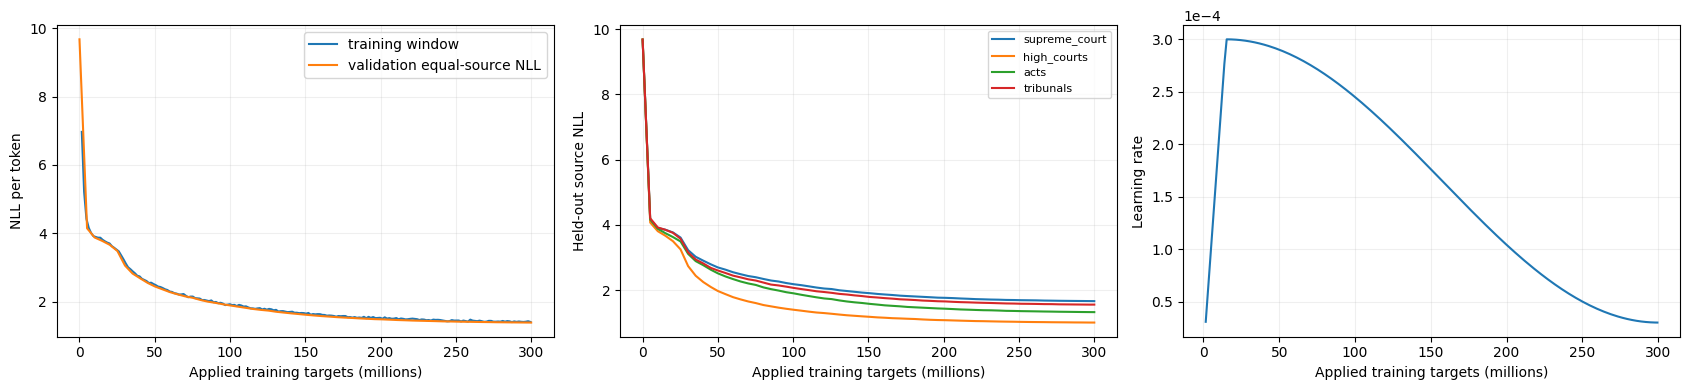

Latest validation: {'type': 'validation', 'optimizer_updates': 4883, 'tokens_in_applied_updates': 300011520, 'validation_nll': 1.387248873517011, 'validation_perplexity': 4.003819872356219, 'validation_token_nll': 1.389258255220186, 'sources': {'supreme_court': {'nll': 1.6623480191458688, 'perplexity': 5.271674316157695, 'targets': 189363}, 'high_courts': {'nll': 1.0056319503700857, 'perplexity': 2.733634248261938, 'targets': 182097}, 'acts': {'nll': 1.3250729598969289, 'perplexity': 3.762459853669214, 'targets': 186020}, 'tribunals': {'nll': 1.5559425646551603, 'perplexity': 4.739551754410213, 'targets': 180484}}}


In [22]:
import matplotlib.pyplot as plt
history = read_json(RUN_DIR / 'history.json')
train_rows = [row for row in history if row['type'] == 'training']
val_rows = [row for row in history if row['type'] == 'validation']
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot([r['tokens_in_applied_updates']/1e6 for r in train_rows], [r['train_nll_window'] for r in train_rows], label='training window')
axes[0].plot([r['tokens_in_applied_updates']/1e6 for r in val_rows], [r['validation_nll'] for r in val_rows], label='validation equal-source NLL')
axes[0].set_ylabel('NLL per token'); axes[0].legend()
for source in manifest['source_order']:
    axes[1].plot([r['tokens_in_applied_updates']/1e6 for r in val_rows], [r['sources'][source]['nll'] for r in val_rows], label=source)
axes[1].set_ylabel('Held-out source NLL'); axes[1].legend(fontsize=8)
axes[2].plot([r['tokens_in_applied_updates']/1e6 for r in train_rows], [r['learning_rate_used'] for r in train_rows])
axes[2].set_ylabel('Learning rate'); axes[2].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
for axis in axes:
    axis.set_xlabel('Applied training targets (millions)'); axis.grid(alpha=0.2)
fig.tight_layout(); fig.savefig(RUN_DIR / 'training_curves.png', dpi=160)
plt.show()
print('Latest validation:', val_rows[-1])


## 18. Short generation check

Generate a few held-out continuations from the best validation checkpoint as a qualitative check.


In [23]:
from phase1_generation import generate_predictions
from a1_tokenizer import A1BPETokenizer
with open(PREP_DIR / 'tokenizer_state.pkl', 'rb') as file:
    tok_saved = pickle.load(file)
tokenizer = A1BPETokenizer(); tokenizer.__dict__.update(tok_saved['state'])
assert tok_saved['signature'] == manifest['tokenizer_signature']
best_path = RUN_DIR / 'best_model.pt'
best = torch.load(best_path, map_location='cpu', weights_only=False)
lm = DecoderLM(LMConfig(**best['model_config']))
lm.load_state_dict(best['model_state']); lm = lm.cuda().eval()
del best
all_prompts = read_json(PREP_DIR / 'validation_prompts.json')
all_truths = read_json(PREP_DIR / 'validation_truth.json')
probe_ids = ['val_0000', 'val_0025', 'val_0049']
probe_prompts = {key: all_prompts[key] for key in probe_ids}
probe_root = RUN_DIR / 'short_generation' / sha256_file(best_path)[:12]
samples = {}
for name, mode in [('greedy', 'greedy'), ('top_k_50_t1', 'top_k')]:
    protocol = {'mode': mode, 'temperature': 1.0, 'top_k': 50, 'best_model_sha256': sha256_file(best_path),
                'purpose': '64-token diagnostic; not official evaluator output'}
    predictions, rows = generate_predictions(lm, tokenizer, probe_prompts, probe_root / name,
        protocol, batch_size=3, max_new_tokens=64, target_words=128, seed=456)
    samples[name] = {key: {'prompt': all_prompts[key]['text'], 'reference': all_truths[key]['text'],
                          'generated': predictions[key]['text'], 'diagnostics': rows[key]} for key in probe_ids}
    for key in probe_ids:
        print(name, key, '|', predictions[key]['text'])
atomic_json(probe_root / 'samples.json', samples)
del lm
gc.collect(); torch.cuda.empty_cache()


Generated 3 / 3 prompts
greedy val_0000 | in the nature of a disqualification or a disqualification or a disqualification or a disqualification or a disqualification or a disqualification or a disqualification or a disqualification or
greedy val_0025 | Section 409 of the IPC is liable to be rejected. 5. The complaint was filed on behalf of the complainant against the accused persons under Sections 409, 420, 467, 468
greedy val_0049 | grant of a licence for the construction of a cinema house and for grant of a licence for the construction of a cinema house and for grant of a licence for the
Generated 3 / 3 prompts
top_k_50_t1 val_0000 | void and void. He has, therefore, to follow the procedure of dealing with or dealing with the validity of any immunity which was taken away by a member of the Hous
top_k_50_t1 val_0025 | Article 226 of the Constitution is dismissed. We have, therefore, directed that the complainant be released on bail, if he files bail applications and all necessary docu

## 19. Run backup

Package the run directory and its metadata for transfer or resume. Retain the prepared input and checkpoint artifacts in private storage.


In [24]:
backup_path = Path('/kaggle/working') / f'{RUN_ID}_backup.zip'
required = sum(path.stat().st_size for path in RUN_DIR.rglob('*') if path.is_file())
if shutil.disk_usage('/kaggle/working').free < required + 512 * 2**20:
    raise RuntimeError('Insufficient disk for ZIP copy; save notebook outputs directly or remove an older downloaded ZIP after backing it up.')
make_bundle(RUN_DIR, backup_path, Path('/kaggle/working'))
print('Run backup:', backup_path, '| GiB:', round(backup_path.stat().st_size / 2**30, 3))
from IPython.display import FileLink, display
display(FileLink(str(backup_path)))


Run backup: /kaggle/working/decoder_004_mixed217m_backup.zip | GiB: 3.247


/kaggle/working/decoder_004_mixed217m_backup.zip

## References

The BPE implementation follows Assignments 1 and 3. Causal attention and Transformer blocks follow the CS781 Module 2.3 material. GELU and tied embeddings follow Module 2.4. Mixed precision and gradient accumulation use the PyTorch AMP recipe.

- [Attention Is All You Need](https://arxiv.org/abs/1706.03762)
- [On Layer Normalization in the Transformer Architecture](https://proceedings.mlr.press/v119/xiong20b.html)
- [PyTorch automatic mixed precision examples](https://docs.pytorch.org/docs/stable/notes/amp_examples.html)
